# Lid-Driven Cavity (Navier-Stokes)

This notebook identifies Navier-Stokes coefficients from lid-driven cavity simulations.

**System:** Momentum and continuity equations for incompressible flow.

In [1]:
import numpy as np
import firedrake as fd
from firedrake.pyplot import tricontourf
import matplotlib.pyplot as plt
from wias import recover_homogeneous_relation, CPQR_solver, assemble_weak_library_rows

## Setup and Solvers

In [2]:
def solve_lid_driven_cavity(mesh, nu_true, lid_speed):
    """Solve steady incompressible Navier-Stokes on the unit square."""
    V = fd.VectorFunctionSpace(mesh, "CG", 2)
    Q = fd.FunctionSpace(mesh, "CG", 1)
    Z = V * Q

    up = fd.Function(Z, name="up")
    u, p = fd.split(up)
    v, q = fd.TestFunctions(Z)

    F = nu_true * fd.inner(fd.grad(u), fd.grad(v)) * fd.dx
    F += fd.inner(fd.dot(fd.grad(u), u), v) * fd.dx
    F -= p * fd.div(v) * fd.dx
    F += q * fd.div(u) * fd.dx

    lid_velocity = fd.Constant((0.0, 0.0))
    bc_walls = fd.DirichletBC(Z.sub(0), fd.Constant((0.0, 0.0)), (1, 2, 3))
    bc_lid = fd.DirichletBC(Z.sub(0), lid_velocity, 4)
    bcs = [bc_walls, bc_lid]

    nullspace = fd.MixedVectorSpaceBasis(
        Z, [Z.sub(0), fd.VectorSpaceBasis(constant=True, comm=fd.COMM_WORLD)]
    )

    solver_params = {
        "snes_type": "newtonls",
        "snes_linesearch_type": "bt",
        "snes_rtol": 1e-10,
        "snes_atol": 1e-12,
        "snes_max_it": 80,
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    }

    lid_velocity.assign((lid_speed, 0.0))
    fd.solve(F == 0, up, bcs=bcs, nullspace=nullspace, solver_parameters=solver_params)

    u_sol, p_sol = up.subfunctions
    u_sol.rename("u")
    p_sol.rename("p")
    return u_sol, p_sol, V

In [3]:
# Parameters
nu_true = 1e-3
lid_speed = 1.0

# Mesh
mesh = fd.UnitSquareMesh(100, 100)
print(f"Mesh: {mesh.num_vertices()} vertices, {mesh.num_cells()} cells")

# output = fd.VTKFile("lid_driven_cavity_ns_with_div.pvd")
print(f"Solving for lid speed {lid_speed}...")
u, p, V = solve_lid_driven_cavity(mesh, nu_true, lid_speed)

Mesh: 10201 vertices, 20000 cells
Solving for lid speed 1.0...


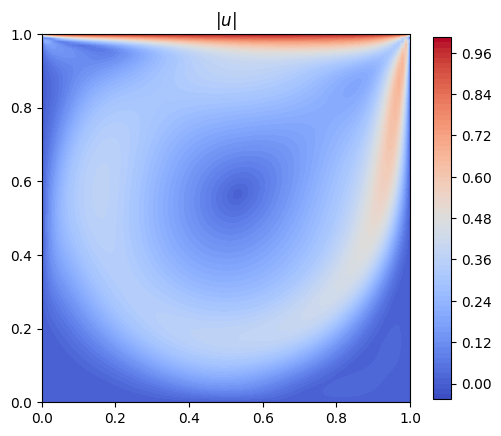

In [4]:
# plot velocity and pressure fields
fig1 = plt.figure(figsize=(10, 5))
u_mag = fd.Function(p.function_space())
u_mag.project(fd.sqrt(u.sub(0)**2 + u.sub(1)**2))
ax1 = fig1.add_subplot(121)
contour_f = tricontourf(u_mag, levels=100, axes=ax1, cmap="coolwarm")
ax1.set_title(r"$|u|$")
ax1.set_aspect("equal")
cbar1 = fig1.colorbar(contour_f, ax=ax1, shrink=0.77)
plt.tight_layout()

## Library Definitions

In [5]:
def momentum_library_fn(u, p, v):
    """Momentum equation library terms."""
    ux, uy = u[0], u[1]
    return {
        "Dx u_x Dx v_x": fd.Dx(ux, 0) * fd.Dx(v[0], 0) * fd.dx,
        "Dx u_x Dy v_x": fd.Dx(ux, 0) * fd.Dx(v[0], 1) * fd.dx,
        "Dy u_x Dx v_x": fd.Dx(ux, 1) * fd.Dx(v[0], 0) * fd.dx,
        "Dy u_x Dy v_x": fd.Dx(ux, 1) * fd.Dx(v[0], 1) * fd.dx,
        "Dx u_y Dx v_y": fd.Dx(uy, 0) * fd.Dx(v[1], 0) * fd.dx,
        "Dx u_y Dy v_y": fd.Dx(uy, 0) * fd.Dx(v[1], 1) * fd.dx,
        "Dy u_y Dx v_y": fd.Dx(uy, 1) * fd.Dx(v[1], 0) * fd.dx,
        "Dy u_y Dy v_y": fd.Dx(uy, 1) * fd.Dx(v[1], 1) * fd.dx,
        "ux Dx u_x": ux * fd.Dx(ux, 0) * v[0] * fd.dx,
        "ux Dy u_x": ux * fd.Dx(ux, 1) * v[0] * fd.dx,
        "uy Dx u_x": uy * fd.Dx(ux, 0) * v[0] * fd.dx,
        "uy Dy u_x": uy * fd.Dx(ux, 1) * v[0] * fd.dx,
        "ux Dx u_y": ux * fd.Dx(uy, 0) * v[1] * fd.dx,
        "ux Dy u_y": ux * fd.Dx(uy, 1) * v[1] * fd.dx,
        "uy Dx u_y": uy * fd.Dx(uy, 0) * v[1] * fd.dx,
        "uy Dy u_y": uy * fd.Dx(uy, 1) * v[1] * fd.dx,
    }


def continuity_library_fn(u, v):
    """Continuity equation library terms."""
    ux, uy = u[0], u[1]
    return {
        "Dx u_x phi": fd.Dx(ux, 0) * v * fd.dx,
        "Dy u_y phi": fd.Dx(uy, 1) * v * fd.dx,
        "Dx u_y phi": fd.Dx(uy, 0) * v * fd.dx,
        "Dy u_x phi": fd.Dx(ux, 1) * v * fd.dx
    }


## Momentum Equation Analysis

In [6]:
# True coefficients for reference (pressure moved to RHS, so only non-pressure terms here)
momentum_true_coeffs = {
    "Dx u_x Dx v_x": nu_true,
    "Dx u_x Dy v_x": 0.0,
    "Dy u_x Dx v_x": 0.0,
    "Dy u_x Dy v_x": nu_true,
    "Dx u_y Dx v_y": nu_true,
    "Dx u_y Dy v_y": 0.0,
    "Dy u_y Dx v_y": 0.0,
    "Dy u_y Dy v_y": nu_true,
    "ux Dx u_x": 1.0,
    "ux Dy u_x": 0.0,
    "uy Dx u_x": 0.0,
    "uy Dy u_x": 1.0,
    "ux Dx u_y": 1.0,
    "ux Dy u_y": 0.0,
    "uy Dx u_y": 0.0,
    "uy Dy u_y": 1.0,
}

continuity_true_coeffs = {
    "Dx u_x phi": 1.0,
    "Dy u_y phi": 1.0,
    "Dx u_y phi": 0.0,
    "Dy u_x phi": 0.0,
}

# Build momentum system including pressure term, then move pressure to RHS
#A_mom, mom_names = build_homogeneous_system_with_pressure_generic(
#    velocities,
#    pressures,
#    V_k,
#    momentum_library_fn,
#)
bc_walls = fd.DirichletBC(V, fd.Constant((0.0, 0.0)), (1, 2, 3))
bc_lid = fd.DirichletBC(V, lid_speed, 4)
bcs = [bc_walls, bc_lid]

library_expressions = momentum_library_fn(u, p, fd.TestFunction(V))
rhs = p*fd.div(fd.TestFunction(V))*fd.dx
A, b = assemble_weak_library_rows(library_expressions, rhs, bcs)

# Solve inhomogeneous system using CPQR (handles dependent columns internally)
x = CPQR_solver(A, b)
momentum_coeffs = dict(zip(momentum_true_coeffs.keys(), x))

Condition number of reduced system: 2784.8863608564798


## Continuity Equation Analysis

In [7]:
# Build continuity system using generic dictionary assembly
#W = fd.FunctionSpace(mesh, "CG", 2)
Q = p.function_space()
continuity_library = continuity_library_fn(u, fd.TestFunction(Q))
rhs = fd.Constant(0.0)*fd.TestFunction(Q)*fd.dx

A, b = assemble_weak_library_rows(continuity_library, rhs)


x, _, div_residual = recover_homogeneous_relation(A)
continuity_coeffs = dict(zip(continuity_true_coeffs.keys(), x))

print(f"Continuity system shape={A.shape}")
print(f"Continuity residual ||A*theta||={div_residual:.3e}")

print(f"Condition number of A: {np.linalg.cond(A):.3e}")


Singular values: [3.96003561e-02 2.70406364e-02 1.20864690e-02 1.70672433e-16]
Continuity system shape=(10201, 4)
Continuity residual ||A*theta||=2.358e-16
Condition number of A: 2.320e+14


## Results

In [8]:
print("\n" + "="*60)
print("CONTINUITY EQUATION RELATION")
print("="*60)
for n in continuity_true_coeffs.keys():
    c = continuity_coeffs.get(n, np.nan)
    true_c = continuity_true_coeffs.get(n, 0.0)
    err = c - true_c
    print(f"  {n}: {c:.6f} (true {true_c:.6f}, error {err:.3e})")

print("\n" + "="*60)
print("MOMENTUM EQUATION COEFFICIENTS")
print("="*60)

for n in momentum_true_coeffs.keys():
    c = momentum_coeffs.get(n, np.nan)
    true_c = momentum_true_coeffs.get(n, 0.0)
    err = c - true_c
    print(f"  {n}: {c:.6f} (true {true_c:.6f}, error {err:.3e})")



CONTINUITY EQUATION RELATION
  Dx u_x phi: 1.000000 (true 1.000000, error 0.000e+00)
  Dy u_y phi: 1.000000 (true 1.000000, error 6.661e-16)
  Dx u_y phi: -0.000000 (true 0.000000, error -3.311e-16)
  Dy u_x phi: 0.000000 (true 0.000000, error 8.766e-18)

MOMENTUM EQUATION COEFFICIENTS
  Dx u_x Dx v_x: 0.001000 (true 0.001000, error -2.385e-18)
  Dx u_x Dy v_x: 0.000000 (true 0.000000, error 0.000e+00)
  Dy u_x Dx v_x: -0.000000 (true 0.000000, error -2.489e-17)
  Dy u_x Dy v_x: 0.001000 (true 0.001000, error 1.106e-17)
  Dx u_y Dx v_y: 0.001000 (true 0.001000, error -1.795e-16)
  Dx u_y Dy v_y: 0.000000 (true 0.000000, error 0.000e+00)
  Dy u_y Dx v_y: 0.000000 (true 0.000000, error 5.551e-16)
  Dy u_y Dy v_y: 0.001000 (true 0.001000, error -1.355e-16)
  ux Dx u_x: 1.000000 (true 1.000000, error -2.975e-14)
  ux Dy u_x: -0.000000 (true 0.000000, error -8.037e-16)
  uy Dx u_x: 0.000000 (true 0.000000, error 4.605e-14)
  uy Dy u_x: 1.000000 (true 1.000000, error 2.953e-14)
  ux Dx u_y: